<a href="https://colab.research.google.com/github/Nabonita-Das/HW-8/blob/main/hw%238/CNN_cat_dog.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HW#8 - Part 2: CNN for Cat and Dog Classification (Keras)

**Author:** Nabonita Das
**Course:** ECE-5831

**Goal:** Build a Convolutional Neural Network (CNN) with Keras that classifies images as **cat** or **dog**.

**What this notebook does**
1. Auto-detects the Cat and Dog dataset (`data_from_kaggle.zip` or a folder), extracts it and finds the separate **train** and **test** images.
2. Prepares **training / validation / testing** datasets (validation = 20% of the training images).
3. Builds and trains a CNN for **10 epochs**.
4. Evaluates on the **validation** and **test** sets (accuracy, precision, recall, F1, ROC-AUC, confusion matrix).
5. **Visualizes predictions** and compares predicted labels with the true labels.
6. Runs automatic checks to verify that training and testing work properly, and saves the model and results.

Works on Windows / Mac / Linux (VS Code, Jupyter) and in Google Colab.

In [5]:
import os, sys, json, random, zipfile, pathlib, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
#tf.config.set_visible_devices([], "GPU")   # CPU-only version: ignore any GPU
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

try:                                    # running inside Google Colab?
    from google.colab import drive, files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("Python    :", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("Colab     :", IN_COLAB)
gpus = tf.config.list_physical_devices("GPU")
print("Device    : CPU only (this is the CPU version)")

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

Python    : 3.13.16
TensorFlow: 2.21.0
Colab     : True
Device    : CPU only (this is the CPU version)


In [6]:
import tensorflow as tf
print("Available GPUs:", tf.config.list_physical_devices('GPU'))

Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Configuration and automatic dataset detection

The notebook looks for the dataset automatically, in this order:

1. `DATA_DIR` / the `CAT_DOG_DIR` environment variable (if set)
2. `USER_DATASET_PATH` - **your path is already filled in below**
3. `data_from_kaggle(.zip)` or `cat_dog_dataset(.zip)` in the current folder, `Downloads`, `Desktop`, `Documents`, Colab `/content`, or Google Drive `MyDrive`
4. Any zip in `Downloads` / the current folder whose name contains `kaggle` or `cat`+`dog`
5. **Colab only:** a file-upload dialog opens so you can upload the zip
6. Last resort: downloads the public `cats_and_dogs_filtered` dataset (a warning is printed - use the Canvas dataset for your final submission)

Set `DATA_SOURCE` to `"drive"` to mount Google Drive and read `DRIVE_PATH` (best for large zips in Colab).

In [7]:
# ============================ SETTINGS ============================
USER_DATASET_PATH = r"C:\Users\manid\Downloads\data_from_kaggle.zip"   # zip file OR folder
DATA_SOURCE = "auto"          # "auto" | "local" | "upload" | "drive" | "download"
DRIVE_PATH  = "/content/drive/MyDrive/data_from_kaggle.zip"
DATA_DIR    = os.environ.get("CAT_DOG_DIR", "")

IMG_SIZE   = (96, 96)         # smaller images = faster on CPU (use (128, 128) for a bit more accuracy)
BATCH_SIZE = 32
EPOCHS     = 10               # required by the assignment
VAL_FRAC   = 0.20             # validation share of the training images (80/20 split)
CACHE      = True             # cache decoded images in RAM (much faster after epoch 1)
# ==================================================================

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}
CLASS_NAMES = ["cat", "dog"]  # label 0 = cat, label 1 = dog


def candidate_paths():
    home = pathlib.Path.home()
    bases = [pathlib.Path("."), home / "Downloads", home / "Desktop", home / "Documents",
             pathlib.Path("/content"), pathlib.Path("/content/drive/MyDrive"), pathlib.Path("/mnt/data")]
    names = ["data_from_kaggle", "cat_dog_dataset", "dogs-vs-cats", "cats_and_dogs"]
    cands = [DATA_DIR, USER_DATASET_PATH]
    for n in names:
        for b in bases:
            cands += [str(b / n), str(b / (n + ".zip"))]
    for b in bases:                                   # name-pattern fallback
        if b.is_dir():
            for pat in ("*kaggle*.zip", "*cat*dog*.zip", "*dog*cat*.zip"):
                cands += [str(p) for p in b.glob(pat)]
    return [c for c in cands if c]


def has_images(folder):
    for _, _, fs in os.walk(folder):
        if any(pathlib.Path(f).suffix.lower() in IMG_EXT for f in fs):
            return True
    return False


def extract_zip(zip_path):
    base = pathlib.Path("/content") if IN_COLAB else pathlib.Path("data_extracted")
    dest = base / (pathlib.Path(zip_path).stem + "_extracted")
    if not (dest.is_dir() and has_images(str(dest))):
        print(f"Extracting {zip_path}  ->  {dest}  (this can take a minute) ...")
        dest.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(dest)
        for nested in list(dest.rglob("*.zip")):      # zips inside the zip (e.g. train.zip)
            with zipfile.ZipFile(nested) as z:
                z.extractall(nested.with_suffix(""))
    return str(dest)


found = None
if DATA_SOURCE == "drive":
    assert IN_COLAB, 'DATA_SOURCE = "drive" only works in Google Colab'
    drive.mount("/content/drive")
    found = DRIVE_PATH
elif DATA_SOURCE in ("auto", "local"):
    found = next((p for p in candidate_paths() if os.path.exists(p)), None)

if found is None and IN_COLAB and DATA_SOURCE in ("auto", "upload"):
    print("Dataset not found - select the Cat and Dog dataset .zip file ...")
    up = files.upload()
    zips = [f for f in up if f.lower().endswith(".zip")]
    found = os.path.join("/content", zips[0]) if zips else None

USED_FALLBACK = False
if found is None and DATA_SOURCE in ("auto", "download"):
    print("WARNING: your dataset was not found - downloading the public cats_and_dogs_filtered dataset instead.")
    zp = keras.utils.get_file("cats_and_dogs_filtered.zip",
                              origin="https://storage.googleapis.com/mledu-datasets/cats_and_dogs_filtered.zip",
                              extract=True)
    root = os.path.dirname(zp)
    found = next(c for c in [os.path.join(root, "cats_and_dogs_filtered"), zp, root] if os.path.isdir(c))
    USED_FALLBACK = True

assert found is not None and os.path.exists(found), (
    "Dataset not found. Put data_from_kaggle.zip in your Downloads folder / next to this notebook, "
    "or set USER_DATASET_PATH above.")

DATA_DIR = extract_zip(found) if (os.path.isfile(found) and found.lower().endswith(".zip")) else found
assert has_images(DATA_DIR), f"No images found inside {DATA_DIR!r}"
print("Dataset source :", found)
print("Dataset folder :", os.path.abspath(DATA_DIR))

Extracting data_from_kaggle.zip  ->  /content/data_from_kaggle_extracted  (this can take a minute) ...
Dataset source : data_from_kaggle.zip
Dataset folder : /content/data_from_kaggle_extracted


## 2. Prepare the training, validation and testing datasets

Every image is labelled from its folder name (`cat`/`cats`, `dog`/`dogs`) or its file name (`cat.123.jpg`). Images inside a `train` folder go to training, images inside a `test` folder go to testing. The **validation set is split off the training images (80/20)**. If the dataset has no `test` (or `validation`) folder, the missing split is created automatically. Corrupted image files are detected and skipped.

Images found per folder type: {'train': 19989, 'val': 0, 'test': 5000, 'none': 0}
Corrupted images skipped: 0 | unlabeled images skipped: 0

split         total    cats    dogs
train         15991    8000    7991
validation     3998    2000    1998
test           5000    2500    2500


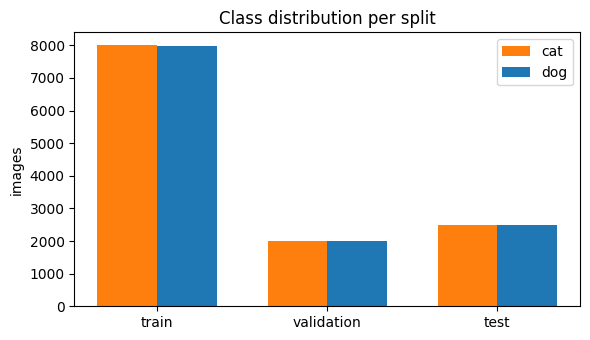

In [8]:
def infer_label(parts):
    """parts = lower-cased path components relative to DATA_DIR (last = file name)."""
    for p in reversed(parts[:-1]):
        if p in ("cat", "cats"): return 0
        if p in ("dog", "dogs"): return 1
    name = parts[-1]
    if name.startswith("cat"): return 0
    if name.startswith("dog"): return 1
    return None


def infer_split(parts):
    for p in parts[:-1]:
        if p in ("train", "training"): return "train"
        if p in ("val", "valid", "validation"): return "val"
        if p in ("test", "testing"): return "test"
    return "none"


items = {"train": [], "val": [], "test": [], "none": []}
n_bad = n_unlabeled = 0
for root, _, fnames in os.walk(DATA_DIR):
    if "__MACOSX" in root:
        continue
    for f in fnames:
        if pathlib.Path(f).suffix.lower() not in IMG_EXT or f.startswith("._"):
            continue
        full = os.path.join(root, f)
        parts = [p.lower() for p in pathlib.Path(os.path.relpath(full, DATA_DIR)).parts]
        label = infer_label(parts)
        if label is None:
            n_unlabeled += 1    # unlabeled image (e.g. Kaggle test/1.jpg) -> cannot be used
            continue
        try:                    # skip corrupted / unreadable image files
            with Image.open(full) as im:
                im.verify()
        except Exception:
            n_bad += 1
            continue
        items[infer_split(parts)].append((full, label))

print("Images found per folder type:", {k: len(v) for k, v in items.items()})
print(f"Corrupted images skipped: {n_bad} | unlabeled images skipped: {n_unlabeled}")


def split_off(data, frac, rng):
    """Stratified split. Returns (remaining, split_off_part)."""
    rest, part = [], []
    for c in (0, 1):
        cls = [d for d in data if d[1] == c]
        rng.shuffle(cls)
        k = int(round(frac * len(cls)))
        part += cls[:k]; rest += cls[k:]
    rng.shuffle(rest); rng.shuffle(part)
    return rest, part


rng = random.Random(SEED)
train_items = items["train"] + items["none"]
val_items, test_items = items["val"], items["test"]

if not test_items and not val_items:
    train_items, test_items = split_off(train_items, 0.15, rng)
    train_items, val_items = split_off(train_items, VAL_FRAC, rng)
elif not test_items:
    train_items, test_items = split_off(train_items, 0.15, rng)
elif not val_items:
    train_items, val_items = split_off(train_items, VAL_FRAC, rng)

assert len(train_items) and len(val_items) and len(test_items), "Could not build all three splits"

splits = {"train": train_items, "validation": val_items, "test": test_items}
print(f"\n{'split':<11}{'total':>8}{'cats':>8}{'dogs':>8}")
for name, d in splits.items():
    n_cat = sum(1 for _, l in d if l == 0)
    print(f"{name:<11}{len(d):>8}{n_cat:>8}{len(d) - n_cat:>8}")

# class distribution plot
fig, ax = plt.subplots(figsize=(6, 3.5))
w = 0.35
for k, (name, d) in enumerate(splits.items()):
    n_cat = sum(1 for _, l in d if l == 0)
    ax.bar(k - w / 2, n_cat, w, color="tab:orange", label="cat" if k == 0 else None)
    ax.bar(k + w / 2, len(d) - n_cat, w, color="tab:blue", label="dog" if k == 0 else None)
ax.set_xticks(range(3)); ax.set_xticklabels(splits.keys())
ax.set_ylabel("images"); ax.set_title("Class distribution per split"); ax.legend()
plt.tight_layout(); plt.show()

batch images: (32, 96, 96, 3) <dtype: 'uint8'> | batch labels: (32,)


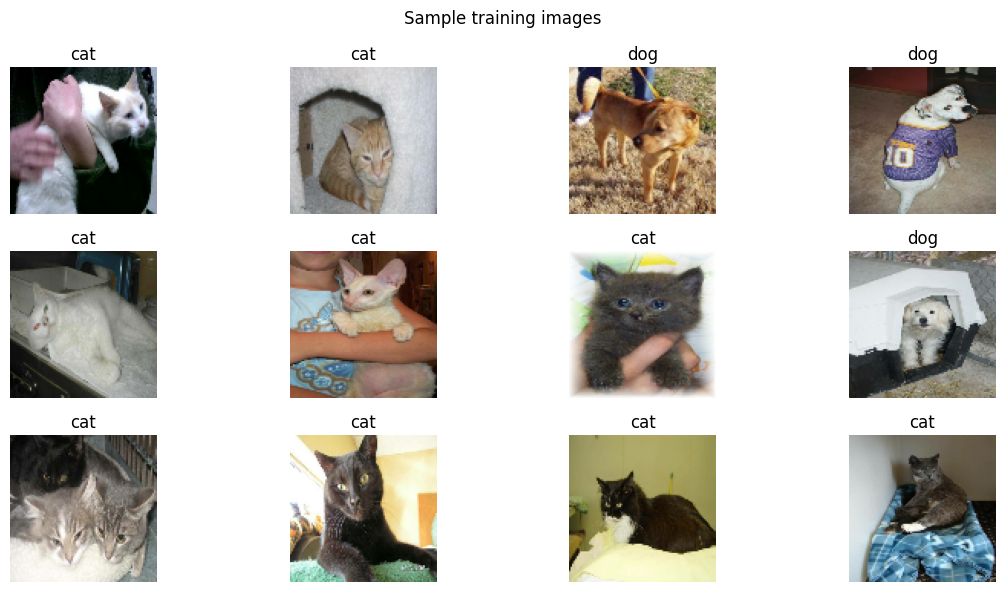

In [9]:
AUTOTUNE = tf.data.AUTOTUNE


def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(tf.round(img), tf.uint8)      # uint8 keeps the RAM cache small
    img.set_shape((*IMG_SIZE, 3))
    return img, tf.cast(label, tf.float32)


def make_ds(data, shuffle=False):
    paths = [p for p, _ in data]
    labels = [l for _, l in data]
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if CACHE:
        ds = ds.cache()
    if shuffle:
        ds = ds.shuffle(2048, seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds = make_ds(train_items, shuffle=True)
val_ds = make_ds(val_items)
test_ds = make_ds(test_items)

images, labels = next(iter(train_ds))
print("batch images:", images.shape, images.dtype, "| batch labels:", labels.shape)
plt.figure(figsize=(12, 6))
for i in range(min(12, len(images))):
    plt.subplot(3, 4, i + 1)
    plt.imshow(images[i].numpy())
    plt.title(CLASS_NAMES[int(labels[i])])
    plt.axis("off")
plt.suptitle("Sample training images")
plt.tight_layout()
plt.show()

## 3. Build the CNN

```
Input (96x96x3)
-> Rescaling (1/255)
-> Data augmentation (random flip / rotation / zoom, active only during training)
-> [Conv2D(32) -> MaxPool] -> [Conv2D(64) -> MaxPool] -> [Conv2D(128) -> MaxPool] -> [Conv2D(128) -> MaxPool]
-> Flatten -> Dropout(0.5) -> Dense(128, ReLU) -> Dense(1, Sigmoid)
```
Binary cross-entropy loss and the Adam optimizer are used because there are two classes.

In [10]:
def build_cnn(input_shape=(*IMG_SIZE, 3)):
    inputs = keras.Input(shape=input_shape)
    x = layers.Rescaling(1.0 / 255)(inputs)

    # data augmentation (only active during training)
    x = layers.RandomFlip("horizontal")(x)
    x = layers.RandomRotation(0.1)(x)
    x = layers.RandomZoom(0.1)(x)

    for filters in (32, 64, 128, 128):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D(2)(x)

    x = layers.Flatten()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = keras.Model(inputs, outputs, name="cnn_cat_dog")
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="binary_crossentropy",
                  metrics=["accuracy"])
    return model


model = build_cnn()
model.summary()

Model: "cnn_cat_dog"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 96, 96, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 96, 96, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 830,913 (3.17 MB)

 Trainable params: 830,913 (3.17 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Train the CNN on the training dataset (epochs = 10)

Two callbacks help training without changing the number of epochs: `ModelCheckpoint` keeps the weights of the best epoch (by validation accuracy) and `ReduceLROnPlateau` lowers the learning rate if the validation loss stops improving. All 10 epochs are always run.

In [11]:
callbacks = [
    keras.callbacks.ModelCheckpoint(os.path.join(RESULTS_DIR, "best_cnn_cat_dog.keras"),
                                    monitor="val_accuracy", save_best_only=True, verbose=0),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
]

t0 = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks)
train_minutes = (time.time() - t0) / 60
print(f"\nTraining finished in {train_minutes:.1f} minutes")

# use the best epoch's weights for the final evaluation
best_epoch = int(np.argmax(history.history["val_accuracy"])) + 1
model = keras.models.load_model(os.path.join(RESULTS_DIR, "best_cnn_cat_dog.keras"))
print(f"Restored weights from best epoch: {best_epoch} (val accuracy = {max(history.history['val_accuracy']):.4f})")

Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 28s 37ms/step - accuracy: 0.5676 - loss: 0.6778 - val_accuracy: 0.6298 - val_loss: 0.6400 - learning_rate: 0.0010
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.6582 - loss: 0.6176 - val_accuracy: 0.6808 - val_loss: 0.5800 - learning_rate: 0.0010
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.7040 - loss: 0.5662 - val_accuracy: 0.7181 - val_loss: 0.5437 - learning_rate: 0.0010
Epoch 4/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.7325 - loss: 0.5334 - val_accuracy: 0.7206 - val_loss: 0.5366 - learning_rate: 0.0010
Epoch 5/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.7583 - loss: 0.4968 - val_accuracy: 0.7791 - val_loss: 0.4724 - learning_rate: 0.0010
Epoch 6/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.7722 - loss: 0.4777 - val_accuracy: 0.7949 - val_loss: 0.4402 - learning_rate: 0.0010
Epoch 7/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.7854 - loss: 

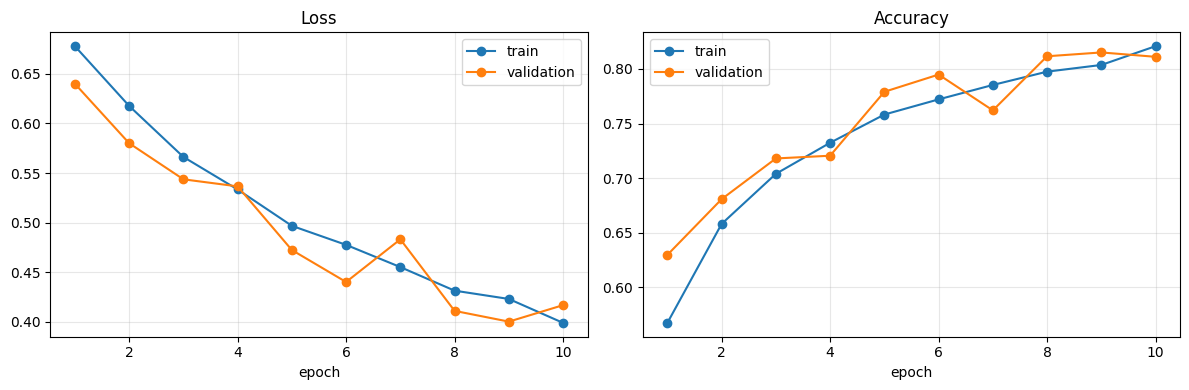

epoch     loss      acc  val_loss  val_acc
    1   0.6778   0.5676    0.6400   0.6298
    2   0.6176   0.6582    0.5800   0.6808
    3   0.5662   0.7040    0.5437   0.7181
    4   0.5334   0.7325    0.5366   0.7206
    5   0.4968   0.7583    0.4724   0.7791
    6   0.4777   0.7722    0.4402   0.7949
    7   0.4553   0.7854    0.4832   0.7621
    8   0.4315   0.7976    0.4112   0.8117
    9   0.4232   0.8037    0.4003   0.8152
   10   0.3991   0.8209    0.4169   0.8112


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, EPOCHS + 1), history.history["loss"], marker="o", label="train")
ax[0].plot(range(1, EPOCHS + 1), history.history["val_loss"], marker="o", label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(range(1, EPOCHS + 1), history.history["accuracy"], marker="o", label="train")
ax[1].plot(range(1, EPOCHS + 1), history.history["val_accuracy"], marker="o", label="validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "cnn_training_curves.png"), dpi=120)
plt.show()

print(f"{'epoch':>5} {'loss':>8} {'acc':>8} {'val_loss':>9} {'val_acc':>8}")
for e in range(EPOCHS):
    h = history.history
    print(f"{e + 1:>5} {h['loss'][e]:>8.4f} {h['accuracy'][e]:>8.4f} {h['val_loss'][e]:>9.4f} {h['val_accuracy'][e]:>8.4f}")

## 5. Evaluate on the validation and test datasets

In [13]:
def collect_predictions(ds, keep_images=0):
    """Run the model over a (non-shuffled) dataset. Returns true labels, probabilities, some images."""
    y_true, y_prob, imgs = [], [], []
    for xb, yb in ds:
        y_true.append(yb.numpy())
        y_prob.append(model.predict(xb, verbose=0).ravel())
        if keep_images and sum(len(a) for a in imgs) < keep_images:
            imgs.append(xb.numpy())
    out = (np.concatenate(y_true).astype(int), np.concatenate(y_prob))
    return out + ((np.concatenate(imgs) if imgs else None),)


def binary_metrics(y_true, y_prob, thr=0.5):
    y_pred = (y_prob > thr).astype(int)
    tp = int(np.sum((y_pred == 1) & (y_true == 1))); tn = int(np.sum((y_pred == 0) & (y_true == 0)))
    fp = int(np.sum((y_pred == 1) & (y_true == 0))); fn = int(np.sum((y_pred == 0) & (y_true == 1)))
    acc = (tp + tn) / len(y_true)
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    f1 = 2 * prec * rec / max(prec + rec, 1e-12)
    auc = float(tf.keras.metrics.AUC()(y_true, y_prob).numpy())
    return dict(accuracy=acc, precision=prec, recall=rec, f1=f1, auc=auc, tp=tp, tn=tn, fp=fp, fn=fn)


val_true, val_prob, _ = collect_predictions(val_ds)
test_true, test_prob, test_images = collect_predictions(test_ds, keep_images=400)
val_m = binary_metrics(val_true, val_prob)
test_m = binary_metrics(test_true, test_prob)
y_true, y_prob = test_true, test_prob
y_pred = (y_prob > 0.5).astype(int)
test_acc = test_m["accuracy"]

val_loss, val_acc = model.evaluate(val_ds, verbose=0)
test_loss, test_acc_keras = model.evaluate(test_ds, verbose=0)

print(f"{'':<12}{'accuracy':>9}{'precision':>10}{'recall':>8}{'F1':>8}{'ROC-AUC':>9}")
for name, m in (("validation", val_m), ("test", test_m)):
    print(f"{name:<12}{m['accuracy']:>9.4f}{m['precision']:>10.4f}{m['recall']:>8.4f}{m['f1']:>8.4f}{m['auc']:>9.4f}")
print(f"\nKeras evaluate -> validation: loss {val_loss:.4f}, acc {val_acc:.4f} | test: loss {test_loss:.4f}, acc {test_acc_keras:.4f}")
print("(precision / recall / F1 are for the 'dog' class)")

             accuracy precision  recall      F1  ROC-AUC
validation     0.8152    0.7845  0.8689  0.8245   0.9045
test           0.8144    0.7827  0.8704  0.8242   0.9026

Keras evaluate -> validation: loss 0.4003, acc 0.8152 | test: loss 0.4040, acc 0.8144
(precision / recall / F1 are for the 'dog' class)


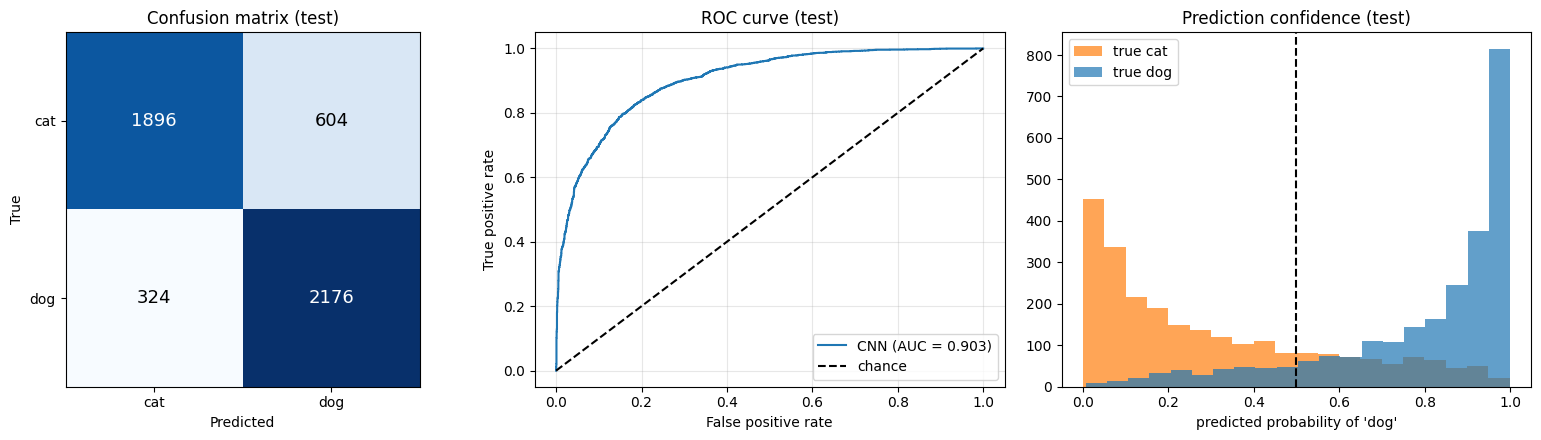

In [14]:
cm = np.array([[test_m["tn"], test_m["fp"]], [test_m["fn"], test_m["tp"]]])   # rows = true [cat, dog]

# ROC curve
order = np.argsort(-y_prob)
ys = y_true[order]
tpr = np.concatenate([[0], np.cumsum(ys) / max(ys.sum(), 1)])
fpr = np.concatenate([[0], np.cumsum(1 - ys) / max((1 - ys).sum(), 1)])

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
im = ax[0].imshow(cm, cmap="Blues")
ax[0].set_xticks([0, 1]); ax[0].set_yticks([0, 1])
ax[0].set_xticklabels(CLASS_NAMES); ax[0].set_yticklabels(CLASS_NAMES)
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True"); ax[0].set_title("Confusion matrix (test)")
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                   color="white" if cm[i, j] > cm.max() / 2 else "black")

ax[1].plot(fpr, tpr, label=f"CNN (AUC = {test_m['auc']:.3f})")
ax[1].plot([0, 1], [0, 1], "k--", label="chance")
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
ax[1].set_title("ROC curve (test)"); ax[1].legend(); ax[1].grid(alpha=0.3)

ax[2].hist(y_prob[y_true == 0], bins=20, alpha=0.7, label="true cat", color="tab:orange")
ax[2].hist(y_prob[y_true == 1], bins=20, alpha=0.7, label="true dog", color="tab:blue")
ax[2].axvline(0.5, color="k", ls="--")
ax[2].set_xlabel("predicted probability of 'dog'"); ax[2].set_title("Prediction confidence (test)"); ax[2].legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "cnn_evaluation.png"), dpi=120)
plt.show()

## 6. Visualize predictions and compare with the true labels

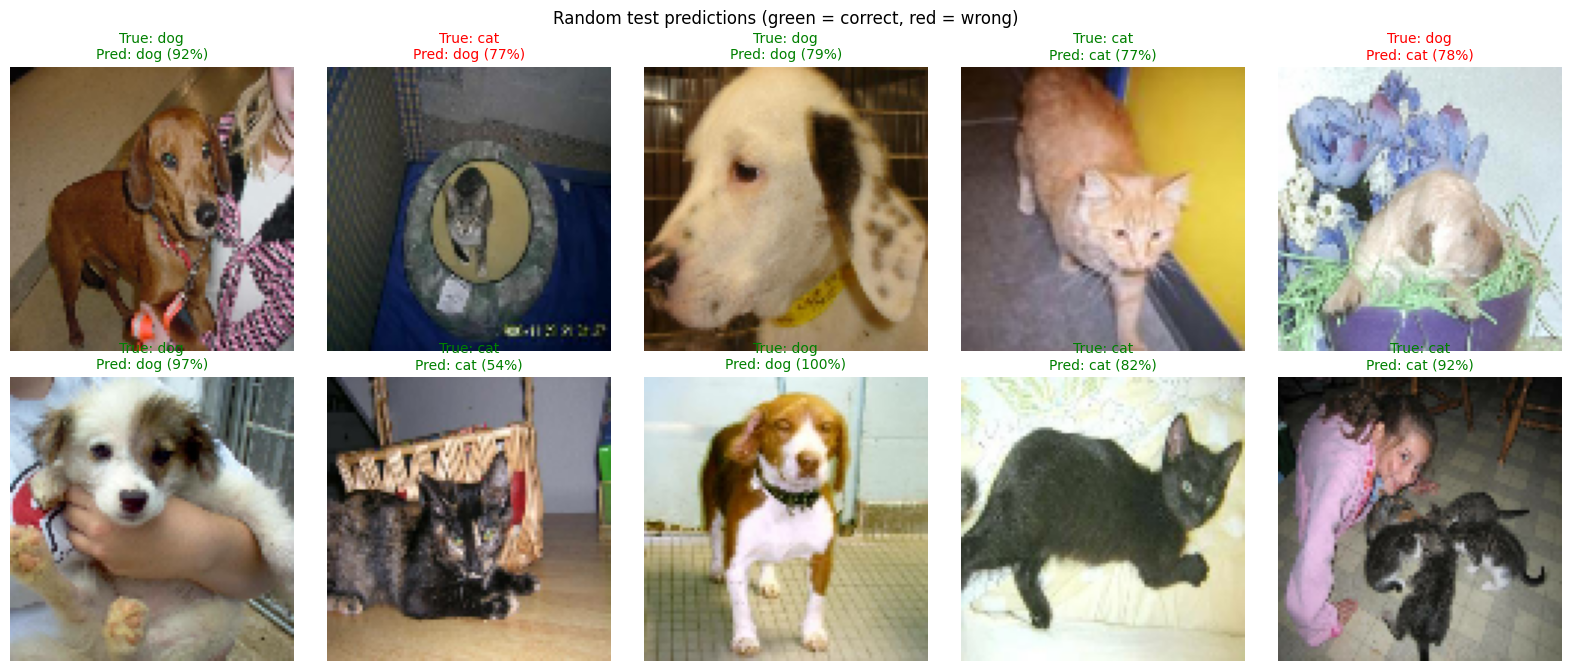

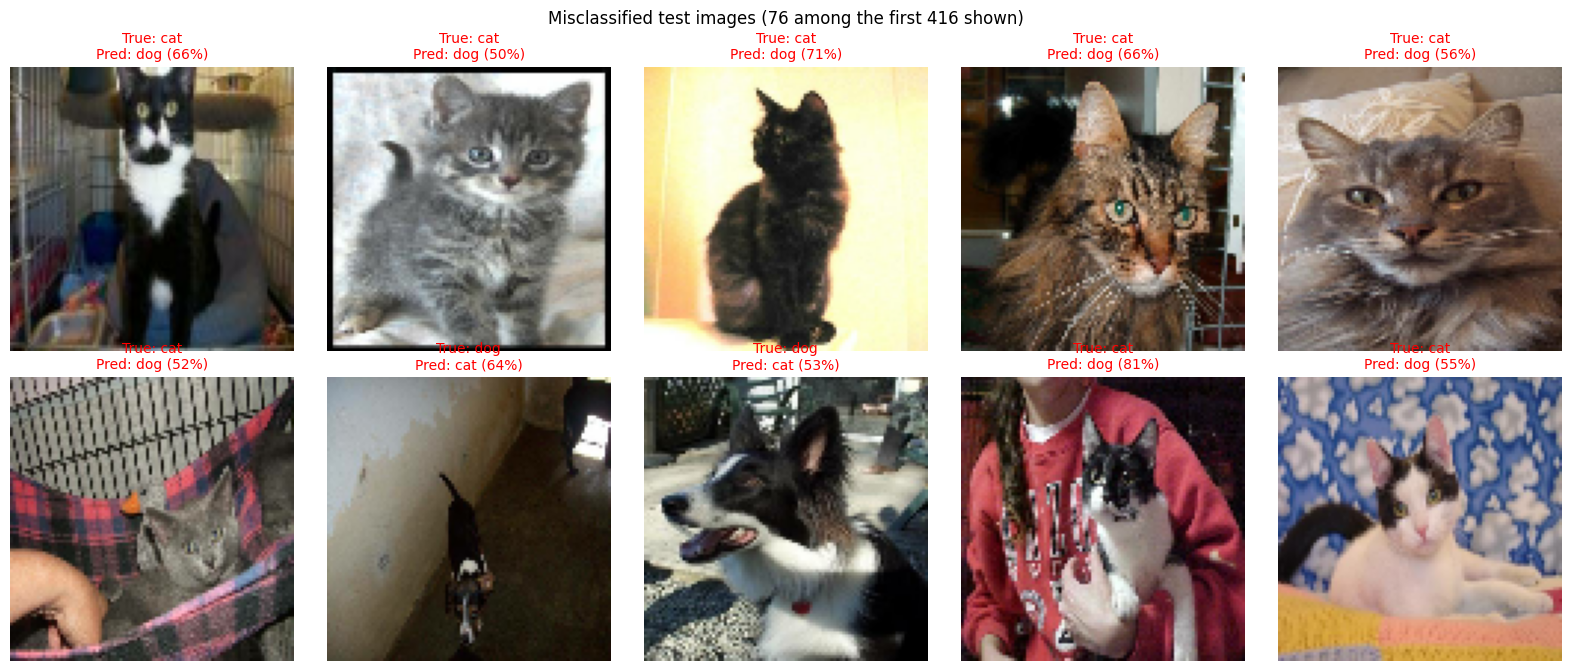

In [15]:
def show_predictions(idx, title, ncols=5):
    idx = list(idx)[:10]
    if not idx:
        print("No examples to show for:", title); return
    nrows = (len(idx) + ncols - 1) // ncols
    plt.figure(figsize=(3.2 * ncols, 3.4 * nrows))
    for k, i in enumerate(idx):
        plt.subplot(nrows, ncols, k + 1)
        plt.imshow(test_images[i].astype("uint8"))
        conf = y_prob[i] if y_pred[i] == 1 else 1 - y_prob[i]
        ok = y_pred[i] == y_true[i]
        plt.title(f"True: {CLASS_NAMES[y_true[i]]}\nPred: {CLASS_NAMES[y_pred[i]]} ({conf:.0%})",
                  color="green" if ok else "red", fontsize=10)
        plt.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


n_img = len(test_images)                      # predictions are in test-set order, images kept for the first n_img
rand_idx = np.random.default_rng(SEED).choice(n_img, min(10, n_img), replace=False)
show_predictions(rand_idx, "Random test predictions (green = correct, red = wrong)")

wrong = [i for i in range(n_img) if y_pred[i] != y_true[i]]
show_predictions(wrong, f"Misclassified test images ({len(wrong)} among the first {n_img} shown)")

## 7. Verify that training and testing work properly

In [16]:
checks = {}

# 1) data pipeline: three non-empty, non-overlapping splits
paths = [set(p for p, _ in d) for d in splits.values()]
checks["train/validation/test splits are non-empty"] = all(len(p) > 0 for p in paths)
checks["no image appears in two splits"] = not (paths[0] & paths[1] or paths[0] & paths[2] or paths[1] & paths[2])

# 2) training ran for exactly the required 10 epochs and learned something
checks["trained for exactly 10 epochs"] = len(history.history["loss"]) == 10
checks["training loss decreased"] = history.history["loss"][-1] < history.history["loss"][0]
checks["training accuracy increased"] = history.history["accuracy"][-1] > history.history["accuracy"][0]

# 3) testing: Keras accuracy == manual accuracy, and the model beats a majority-class guess
manual_acc = float(np.mean(y_pred == y_true))
majority = max(np.mean(y_true == 0), np.mean(y_true == 1))
checks["Keras and manual test accuracy agree"] = abs(manual_acc - test_acc_keras) < 1e-3
checks["test accuracy beats majority-class baseline"] = test_acc > majority
checks["ROC-AUC above 0.5 (better than random)"] = test_m["auc"] > 0.5
checks["predicted probabilities are in [0, 1]"] = bool(np.all((y_prob >= 0) & (y_prob <= 1)))

for name, ok in checks.items():
    print(("PASS  " if ok else "FAIL  ") + name)
print(f"\nTest accuracy {test_acc:.4f} vs. majority-class baseline {majority:.4f}")
assert all(checks.values()), "Some verification checks failed - see above"
print("\nAll verification checks passed.")

PASS  train/validation/test splits are non-empty
PASS  no image appears in two splits
PASS  trained for exactly 10 epochs
PASS  training loss decreased
PASS  training accuracy increased
PASS  Keras and manual test accuracy agree
PASS  test accuracy beats majority-class baseline
PASS  ROC-AUC above 0.5 (better than random)
PASS  predicted probabilities are in [0, 1]

Test accuracy 0.8144 vs. majority-class baseline 0.5000

All verification checks passed.


## 8. Save the model and a results summary

In [17]:
model.save(os.path.join(RESULTS_DIR, "cnn_cat_dog_final.keras"))

summary = {
    "author": "Nabonita Das",
    "dataset": os.path.abspath(DATA_DIR),
    "used_fallback_dataset": USED_FALLBACK,
    "image_size": list(IMG_SIZE), "batch_size": BATCH_SIZE, "epochs": EPOCHS,
    "n_train": len(train_items), "n_validation": len(val_items), "n_test": len(test_items),
    "best_epoch": best_epoch, "training_minutes": round(train_minutes, 2),
    "validation": {k: round(float(v), 4) for k, v in val_m.items()},
    "test": {k: round(float(v), 4) for k, v in test_m.items()},
    "history": {k: [round(float(x), 5) for x in v] for k, v in history.history.items()},
}
with open(os.path.join(RESULTS_DIR, "cnn_results.json"), "w") as f:
    json.dump(summary, f, indent=2)
print("Saved to the 'results' folder:", sorted(os.listdir(RESULTS_DIR)))


def predict_image(path):
    """Classify any single cat/dog image file with the trained model."""
    img, _ = load_image(path, 0)
    p = float(model.predict(img[None], verbose=0)[0, 0])
    label = CLASS_NAMES[int(p > 0.5)]
    plt.imshow(img.numpy()); plt.axis("off"); plt.title(f"{label} ({max(p, 1 - p):.0%})"); plt.show()
    return label, p

# Example:  predict_image(test_items[0][0])

Saved to the 'results' folder: ['best_cnn_cat_dog.keras', 'cnn_cat_dog_final.keras', 'cnn_evaluation.png', 'cnn_results.json', 'cnn_training_curves.png']


## 9. Conclusion

A CNN with four convolution / max-pooling blocks, dropout and a dense classifier was trained for 10 epochs on the cat and dog **training** images, with data augmentation to reduce over-fitting and a 20% **validation** split to monitor training. The model was then evaluated on the separate **test** images. The training curves, accuracy / precision / recall / F1 / ROC-AUC, confusion matrix and the labelled prediction examples above, together with the automatic checks in section 7, show that the training and testing pipeline works properly.

Possible improvements: more epochs, a larger input size (e.g. 200x180), batch normalization, or transfer learning (MobileNetV2 / VGG16).